# Experiment: DACR-AMTP-inspired (LOOSE)

LOOSE VERSION of DACR-AMTP (Cong et al., 2023; 3.40 m at 5 s in HLTP++'s table), known only as 'dynamic attention + context reasoning, multimodal'. Our interpretation: the target re-attends to its neighbours at every history step (dynamic attention), a GRU reasons over that context sequence, and 6 mode queries read the reasoning sequence to produce multimodal futures.

Part of the model comparison in `experiments/MODEL_ALTERNATIVES.md`. Run All; set `DEBUG = False` in section 2 for the real run.

## 0. Decisions & assumptions

Every choice that could change the result is listed here; the cell notes below repeat the ones that apply to each cell.

**Shared by every notebook (S)**

| # | Decision / assumption | Why | Departure from paper / alternative |
|---|---|---|---|
| S1 | Same data for every model: NGSIM us-101 + i-80 (DEBUG: first 250k rows of us-101), scene-level 70/10/20 split, seed 42, train-only normalization. | Differences in the results must come from the model, not the data. | Papers use their own splits, so published numbers are not like-for-like with ours. |
| S2 | Same training budget for every model: config.py defaults (12 epochs, Adam lr 5e-4 decayed x0.6 per epoch, batch 128, weight decay 1e-5, grad clip 1.0). | A fair comparison; per-model tuning would favour whichever model got tuned most. | Each paper's own schedule (e.g. CS-LSTM trains longer with lr 1e-3). Tune later with --mode tune if a model looks under-trained. |
| S3 | Loss = MSE + bivariate-Gaussian NLL + neighbour-goal MSE (`basic_loss`); the risk-scaled loss is used only where this notebook's M table says so (STRAP-R-based variants). Models without a goal head output zero goals, so their goal term is a constant. A model may add its own `aux_loss` (only the diffusion model does). | Keeps one training objective; the risk-scaled loss is STRAP-R's own contribution. | Loss values are therefore not comparable across models: compare RMSE only. |
| S4 | Best checkpoint = lowest validation loss (`fit` default); test RMSE is reported at 1-5 s for that checkpoint. | Same selection rule for every model. | Selecting on val RMSE would be closer to the reported metric. |
| S5 | KNOWN LIMITATION (not fixed): positions are relative to the target at each timestep, so the target's own history is always (0, 0) and lateral speed is always 0 (NGSIM gives longitudinal speed only). The target is seen through speed, acceleration and lane features; lateral context comes from neighbours. | Kept as is (user decision) so every model gets identical inputs. | Papers feed the target's own x/y track; lane-change prediction is handicapped for all models here. |
| S6 | Neighbours = up to 15 risk-selected vehicles (S/O-field > RISK_THRESHOLD), not every nearby vehicle. | Same scene construction as STRAP. | Grid/graph papers use all vehicles in range; ours see only the risk-selected ones. |
| S7 | Output = one bivariate Gaussian per future step (mu_x, mu_y, sigma_x, sigma_y, rho); RMSE uses the mean. Multimodal models are moment-matched to one Gaussian. | The `fit` / `evaluate_trajectory` contract and how STRAP's Table I is scored. | minADE/minFDE over modes would favour multimodal models. |

**Specific to this model (M)**

| # | Decision / assumption | Why | Departure from paper / alternative |
|---|---|---|---|
| M1 | LOOSE VERSION: not enough public detail to reproduce this model; the architecture below is our interpretation of its title/abstract. Results do NOT represent the published model. | User asked for best-effort versions of thin-detail models. | Treat as an extra baseline, not as a reproduction. |
| M2 | Dynamic attention: per history step, target-to-real-vehicles attention on per-vehicle LSTM states. | 'Dynamic' = recomputed every step. | - |
| M3 | Context reasoning: 2-layer GRU over the 30 attention contexts; 6 learned mode queries attend over the GRU outputs. | Our reading of 'context reasoning'. | - |
| M4 | Mode-conditioned LSTM decoder; moment-matched with learned mode weights. | Multimodal output, single-Gaussian contract (S7). | - |

## 1. Setup

**Decisions in this cell:** seed fixed to `SEED` (42) in every notebook so initialisation is not a source of differences (S1).

In [1]:
import sys
from pathlib import Path

# Repo root = first folder upwards that contains src/ (works from experiments/ or the root).
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import time
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

from src.config import (
    BATCH_SIZE, BETA_LOSS, DEBUG_MAX_ROWS, DEVICE, DROPOUT, DT, LEARNING_RATE, LR_DECAY, N_V,
    NGSIM_LOCATIONS, NUM_EPOCHS, NORMALIZATION_FILE, SEED, STATE_DIM, TF_STEPS, TH_STEPS, WEIGHT_DECAY,
)
from src.data.loader import NGSIMDataLoader, create_dataloader
from src.data.normalization import load_stats, normalize_samples
from src.evaluation.evaluate import evaluate_trajectory
from src.models.strap import STRAP
from src.pipeline import collision_scores, metric_rows, test_groups
from src.train import fit, prepare_data
from experiments.benchmark import compare, save_result

torch.manual_seed(SEED)
print("device:", DEVICE)

/home/st_students/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


device: cuda


## 2. Experiment config

**Decisions in this cell:** training budget is config.py's (S2); `use_risk_loss` as in the M table; collisions scored at 2 m like `--mode collisions`.

In [2]:
EXP_NAME = "dacr_amtp"          # unique per notebook -> experiments/results/<EXP_NAME>.json
DESCRIPTION = "LOOSE: per-step dynamic attention + GRU context reasoning, 6 multimodal queries"

DEBUG = False                  # True: DEBUG_MAX_ROWS of us-101 for a quick check; False: full data
LOCATIONS = ["us-101"] if DEBUG else NGSIM_LOCATIONS

HPARAMS = dict(               # keyword args of src.train.fit
    num_epochs=NUM_EPOCHS,
    use_risk_loss=False,       # False = basic loss (STRAP-B style)
    beta=BETA_LOSS,
    learning_rate=LEARNING_RATE,
    batch_size=BATCH_SIZE,
    lr_decay=LR_DECAY,
    weight_decay=WEIGHT_DECAY,
)

RUN_COLLISIONS = False         # per-pair collision scoring on the test split (slow on full data)
COLLISION_THRESHOLD = 2.0     # metres, GT collision label distance

CKPT_DIR = ROOT / "experiments" / "checkpoints" / EXP_NAME

## 3. Data
Train-only normalization stats and the intention codebook are written to `CKPT_DIR`.

**Decisions in this cell:** same loader, split and train-only normalization as every other notebook (S1, S6); `norm_stats` is loaded here so the model (next section) can recover metres and lane numbers.

In [3]:
loader = NGSIMDataLoader(locations=LOCATIONS, max_rows=DEBUG_MAX_ROWS if DEBUG else None)
train_s, val_s, centers = prepare_data(loader, save_dir=str(CKPT_DIR))
_, _, test_raw = loader.get_splits()   # cached; raw (unnormalized) test split
# Train-only mean/std; models that need metres or lane numbers undo the normalization with it.
norm_stats = load_stats(str(CKPT_DIR / NORMALIZATION_FILE))
print(f"train/val/test = {len(train_s)}/{len(val_s)}/{len(test_raw)}")

2026-10-29 12:01:40,159 - STRAP - INFO - [NGSIMLoader] Loading cached data from /home/st_students/MTP/data/raw/ngsim/ngsim_us-101.csv


2026-10-29 12:01:47,754 - STRAP - INFO - [NGSIMLoader] Dropping 704,000 duplicate rows (0 duplicate groups differ in other columns)


2026-10-29 12:01:48,584 - STRAP - INFO - [NGSIMLoader] 'us-101' period 1: 1,180,598 rows, frame_id offset=0


2026-10-29 12:01:48,610 - STRAP - INFO - [NGSIMLoader] 'us-101' period 2: 1,403,095 rows, frame_id offset=9609


2026-10-29 12:01:48,637 - STRAP - INFO - [NGSIMLoader] 'us-101' period 3: 1,515,240 rows, frame_id offset=19680


...

2026-10-29 12:19:27,015 - STRAP - INFO - [Train] Fitting k-means intention codebook on training data...


/usr/lib/python3/dist-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.17.3 and <1.25.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


2026-10-29 12:19:56,771 - STRAP - INFO - [Train] Saved intention codebook ((100, 4)) to /home/st_students/MTP/experiments/checkpoints/dacr_amtp/intention_clusters.pkl


2026-10-29 12:19:58,346 - STRAP - INFO - [NGSIMLoader] Per-recording temporal split over 6 recordings: train=540149 {'i-80': 287507, 'us-101': 252642}, val=86077 {'i-80': 50059, 'us-101': 36018}, test=121130 {'i-80': 58995, 'us-101': 62135}


train/val/test = 540149/86077/121130


## 4. Model

Any `torch.nn.Module` works if `forward(states, mask, dims)` returns a 3-tuple:

| output | shape | meaning |
|---|---|---|
| `traj_dist` | `(B, T_f=50, 5)` | `[mu_x, mu_y, sigma_x, sigma_y, rho]` of the target, metres relative to its last observed position (x longitudinal, y lateral); `sigma > 0`, `rho` in (-1, 1) |
| `goals` | `(B, N-1, 4)` | neighbour goals; a model without a goal head returns `states.new_zeros(B, N - 1, 4)` |
| third | anything | ignored by training/eval (STRAP returns its risk field) |

Inputs: `states (B, T_h=30, N, 11)` normalized (vehicle 0 = target, rest neighbours, zero-padded),
`mask (B, N)` True = real vehicle, `dims (B, N, 2)` raw length/width in metres.
Feature index: 0 rel-longitudinal m, 1 rel-lateral m, 2 speed/30, 3 lateral speed (always 0), 4 accel/10,
5 type/2, 6 relative lane (target - vehicle, left = +), 7 length/10, 8 width/3, 9 S-field risk, 10 O-field risk.
Raw value = `states * std + mean` with `norm_stats`. STRAP's k-means codebook is only loaded if the model has a `risk_decoder`.

**Decisions in this cell:** dynamic attention (M2), GRU reasoning + mode queries (M3), mode decoder (M4).

In [4]:
def moment_match(raw, weights):
    """(B, M, T, 5) raw mode outputs + (B, M) mode weights -> (B, T, 5) one Gaussian (S7)."""
    mu = raw[..., :2]
    sig = F.softplus(raw[..., 2:4]) + 1e-3
    rho = torch.tanh(raw[..., 4])
    w = weights[:, :, None]                                         # (B, M, 1)
    mean = (w[..., None] * mu).sum(1)                               # (B, T, 2)
    d = mu - mean[:, None]
    var = (w[..., None] * (sig ** 2 + d ** 2)).sum(1)
    cov = (w * (rho * sig[..., 0] * sig[..., 1] + d[..., 0] * d[..., 1])).sum(1)
    sx, sy = var[..., 0].sqrt(), var[..., 1].sqrt()
    return torch.stack([mean[..., 0], mean[..., 1], sx, sy, (cov / (sx * sy)).clamp(-0.999, 0.999)], dim=-1)

class VehicleEncoder(nn.Module):
    """Shared per-vehicle encoder: FC + leaky ReLU + LSTM over the 30 history steps."""
    def __init__(self, input_dim=STATE_DIM, emb=32, d=64):
        super().__init__()
        self.embed = nn.Linear(input_dim, emb)
        self.lstm = nn.LSTM(emb, d, batch_first=True)

    def forward(self, x):                                           # x (B, T, N, F)
        B, T, N, D_in = x.shape
        seq, (h, _) = self.lstm(F.leaky_relu(self.embed(x.transpose(1, 2).reshape(B * N, T, D_in)), 0.1))
        return seq.reshape(B, N, T, -1), h[-1].reshape(B, N, -1)   # per-step and last-step encodings

def decode_modes(decoder, head, ctx, weights, T_f=TF_STEPS):
    """ctx (B, M, C): one context per mode, fed at every step of a shared LSTM decoder;
    the M raw outputs are moment-matched with `weights` (B, M) into one Gaussian (S7)."""
    B, M, _ = ctx.shape
    h, _ = decoder(ctx.reshape(B * M, 1, -1).expand(-1, T_f, -1))
    return moment_match(head(h).reshape(B, M, T_f, 5), weights)

class DACRAMTP(nn.Module):
    def __init__(self, d=64, heads=4, dec=128, n_modes=6):
        super().__init__()
        self.encoder = VehicleEncoder(STATE_DIM, 32, d)
        self.dynamic = nn.MultiheadAttention(d, heads, batch_first=True)
        self.reason = nn.GRU(2 * d, d, num_layers=2, batch_first=True)
        self.mode_query = nn.Parameter(torch.randn(n_modes, d) * 0.02)
        self.read = nn.MultiheadAttention(d, heads, batch_first=True)
        self.mode_logits = nn.Linear(d, 1)
        self.decoder = nn.LSTM(2 * d, dec, batch_first=True)
        self.head = nn.Linear(dec, 5)

    def forward(self, states, mask, dims=None):
        B, T_h, N, _ = states.shape
        seq, _ = self.encoder(states)                               # (B, N, T, d)
        q = seq[:, 0].reshape(B * T_h, 1, -1)
        kv = seq.transpose(1, 2).reshape(B * T_h, N, -1)
        pad = (~mask)[:, None].expand(B, T_h, N).reshape(B * T_h, N)
        a, _ = self.dynamic(q, kv, kv, key_padding_mask=pad)
        r, _ = self.reason(torch.cat([seq[:, 0], a.reshape(B, T_h, -1)], -1))   # M3
        modes, _ = self.read(self.mode_query[None].expand(B, -1, -1), r, r)
        mode_ctx = torch.cat([modes, r[:, -1:].expand(-1, modes.shape[1], -1)], -1)
        weights = torch.softmax(self.mode_logits(modes).squeeze(-1), -1)
        return decode_modes(self.decoder, self.head, mode_ctx, weights), states.new_zeros(B, N - 1, 4), None


def build_model():
    return DACRAMTP()

model = build_model().to(DEVICE)
n_params = sum(p.numel() for p in model.parameters())
print(f"{type(model).__name__}: {n_params:,} parameters")

DACRAMTP: 254,150 parameters


## 5. Train

**Decisions in this cell:** `fit` with the config budget (S2); best checkpoint by val loss (S4). Loss curves are only comparable within this notebook (S3).

2026-10-29 12:19:59,590 - STRAP - INFO - Training STRAP on cuda


2026-10-29 12:19:59,591 - STRAP - INFO - Epochs: 12, Risk Loss: False, Beta: 0.0, LR: 0.0005, Batch: 128, LR decay: 0.6, Weight decay: 1e-05


2026-10-29 12:19:59,592 - STRAP - INFO - Number of training batches: 4220


2026-10-29 12:19:59,592 - STRAP - INFO - Number of validation batches: 673


2026-10-29 12:21:19,016 - STRAP - INFO - Epoch 1/12: Train Loss=658.0342 (goal=598.7873, traj=59.2468), Val Loss=392.9682, Val RMSE=2.4021


...

2026-10-29 12:35:10,880 - STRAP - INFO -   -> Saved best checkpoint (val_loss=391.2435)


2026-10-29 12:36:44,769 - STRAP - INFO - Epoch 12/12: Train Loss=604.9427 (goal=598.7873, traj=6.1553), Val Loss=391.1852, Val RMSE=2.0625


2026-10-29 12:36:44,773 - STRAP - INFO -   -> Saved best checkpoint (val_loss=391.1852)


2026-10-29 12:36:44,794 - STRAP - INFO - Training complete!


,epoch,train_loss,goal_loss,traj_loss,val_loss,val_rmse,lr
0,1,658.034169,598.787329,59.246839,392.968209,2.402083,0.000300
1,2,606.608035,598.788202,7.819834,391.762546,2.145702,0.000180
2,3,605.735616,598.788071,6.947545,391.644043,2.134765,0.000108
3,4,605.415802,598.789103,6.626699,391.472839,2.102023,0.000065
4,5,605.215896,598.788086,6.427810,391.389195,2.091765,0.000039
5,6,605.098036,598.787884,6.310152,391.319271,2.083056,0.000023
6,7,605.034834,598.788183,6.246651,391.309943,2.084138,0.000014
7,8,604.993066,598.786516,6.206551,391.263465,2.077241,0.000008
8,9,604.971264,598.786729,6.184535,391.254024,2.075921,0.000005
9,10,604.954916,598.786228,6.168689,391.260022,2.077409,0.000003


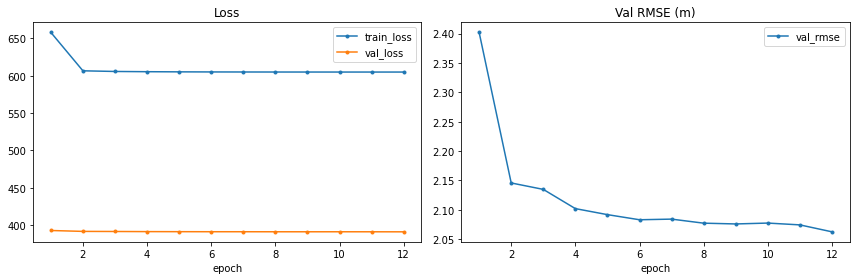

In [5]:
t0 = time.time()
training_log = fit(model, train_s, val_s, centers, save_dir=str(CKPT_DIR), **HPARAMS)
train_minutes = (time.time() - t0) / 60

log_df = pd.DataFrame(training_log)
display(log_df)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
log_df.plot(x="epoch", y=["train_loss", "val_loss"], marker=".", ax=axes[0], title="Loss")
log_df.plot(x="epoch", y="val_rmse", marker=".", ax=axes[1], title="Val RMSE (m)")
plt.tight_layout(); plt.show()

## 6. Evaluate (best checkpoint) — RMSE 1s…5s overall, per site, zero-neighbour scenes

**Decisions in this cell:** RMSE of the predicted mean at 1-5 s on the test split, overall / per site / target-only scenes (S7).

In [6]:
model.load_state_dict(torch.load(CKPT_DIR / "best_model.pt", map_location=DEVICE, weights_only=True))
model.eval()
test_s = normalize_samples(test_raw, norm_stats)

test_metrics = {}
for label, samples in test_groups(test_s).items():
    dl = create_dataloader(samples, batch_size=32, shuffle=False)
    test_metrics[label] = {**evaluate_trajectory(model, dl, DEVICE), "n": len(samples)}
display(pd.DataFrame(test_metrics).T)

,rmse_1s,rmse_2s,rmse_3s,rmse_4s,rmse_5s,rmse_avg,n
NGSIM Test Split,0.460277,1.122143,1.921245,2.909364,4.114448,2.105495,121130.0
site us-101,0.431956,1.077368,1.881477,2.906760,4.179300,2.095372,62135.0
zero-neighbour samples,0.551121,1.315867,2.268480,3.454441,4.896930,2.497368,3120.0
site i-80,0.488332,1.167446,1.962260,2.912107,4.045021,2.115033,58995.0


## 7. Collision prediction (optional)
Model's predicted target vs constant-velocity neighbours, every risk metric at its default threshold.

**Decisions in this cell:** neighbours are rolled forward at constant velocity and candidates are the nearest vehicles at the last history step, as in `--mode collisions`; only the target trajectory comes from this model.

In [7]:
collisions = None
if RUN_COLLISIONS:
    scores, gt, _ = collision_scores(model, loader, test_raw, norm_stats, COLLISION_THRESHOLD)
    collisions = {"threshold": COLLISION_THRESHOLD, "n_pairs": len(gt),
                  "n_gt_collisions": int(gt.sum()), "rows": metric_rows(scores, gt)}
    print(f"{len(gt)} pairs, {int(gt.sum())} GT collisions")
    display(pd.DataFrame(collisions["rows"]).set_index("metric"))

## 8. Save result

**Decisions in this cell:** one JSON per `EXP_NAME`; a rerun overwrites it.

In [8]:
save_result({
    "name": EXP_NAME,
    "description": DESCRIPTION,
    "model_class": type(model).__name__,
    "n_params": n_params,
    "hparams": HPARAMS,
    "data": {"locations": LOCATIONS, "debug": DEBUG},
    "train_minutes": train_minutes,
    "training_log": training_log,
    "test": test_metrics,
    "collisions": collisions,
})

Saved /home/st_students/MTP/experiments/results/dacr_amtp.json


PosixPath('/home/st_students/MTP/experiments/results/dacr_amtp.json')

## 9. Comparison & benchmarking — all results in `experiments/results/`

Ranked by overall test `rmse_avg` (best per column highlighted). Check the `data` column:
debug and full-data runs are listed together but are not comparable.
Also written to `experiments/comparison_rmse.csv` / `comparison_collisions.csv`.

**Decisions in this cell:** compares every saved result; only rows with the same `data` value are like-for-like.

,description,data,epochs,n_params,rmse_1s,rmse_2s,rmse_3s,rmse_4s,rmse_5s,rmse_avg,site us-101 avg,zero-neighbour samples avg,site i-80 avg
model,,,,,,,,,,,,,
dacr_amtp,"LOOSE: per-step dynamic attention + GRU context reasoning, 6 multimodal queries","us-101,i-80",12,254150,0.4603,1.1221,1.9212,2.9094,4.1144,2.1055,2.0954,2.4974,2.1150
cognitive,"Cognitive-driven: safety (TTC/TET/TIT) + behaviour centrality + priority attention, Leanformer fusion","us-101,i-80",12,227979,0.4624,1.1204,1.9247,2.9255,4.1366,2.1139,2.0999,2.5102,2.1276
cf_lstm,"LOOSE: cascaded LSTMs (vehicle states, then target + per-step pooled interaction)","us-101,i-80",12,175109,0.4755,1.1638,2.0026,3.0541,4.3407,2.2073,2.2001,2.5426,2.2135
cs_lstm,CS-LSTM: LSTM encoders + 13x3 convolutional social pooling (unimodal),"us-101,i-80",12,192117,0.4738,1.1644,2.0267,3.1300,4.5015,2.2593,2.2737,2.5803,2.2420
bat,"BAT-style: centrality behaviour features + polar pooling + priority attention, 9 latent manoeuvres","us-101,i-80",12,152015,0.5486,1.2622,2.1246,3.1774,4.4043,2.3034,2.3297,4.3391,2.2746
cdstraj,CDSTraj-style: spatial-temporal interaction encoder + full-trajectory diffusion with a cross-attention transformer denoiser,"us-101,i-80",12,210492,1.1403,1.7166,2.6281,3.8572,5.2860,2.9256,2.9225,3.3681,2.9311
cv,"Constant velocity: last speed rolled forward, no training","us-101,i-80",0,0,0.6021,1.5879,2.8777,4.4704,6.3260,3.1728,3.3161,3.2966,3.0112
c2f_tp,C2F-TP-style: multimodal coarse predictor + conditional diffusion refinement (DDIM),"us-101,i-80",12,475334,5.1482,6.2205,5.8009,7.9724,6.7000,6.3684,6.2802,6.5804,6.4683


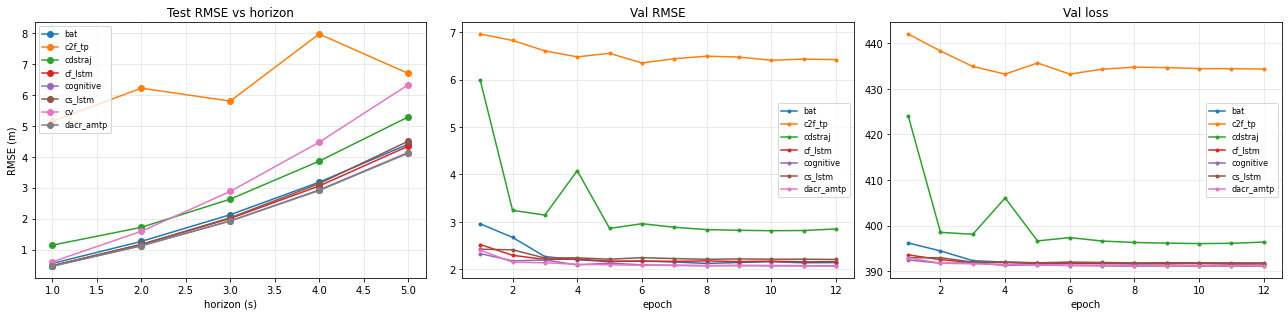

In [9]:
rmse_df, collision_df = compare()